# Task4 — AugMix consistency: Train-only robustness validation

**Run All เริ่ม pilot 1 fold**: fine-tune ResNet18 6 epochs จาก heavy_weighted18 ของ fold เดียวกัน → เทียบ original OOF ทั้ง fold และ stress validation 100 ภาพต่อ class. ไม่โหลด Test ใน pilot หรือ validation. ถ้า pilot ผ่าน ให้เปลี่ยน `RUN_MODE="full"` และ Run All เพื่อทำอีก 4 folds, final corruption audit, full refit และ export เมื่อทุกเกณฑ์ผ่าน.

เปรียบเทียบสูตรที่เคยส่ง **ResNet18 cosine TTA** และ **heavy weighted + sampler ensemble TTA**. Candidate คือ AugMix-finetuned weighted model + sampler เดิมแบบ 50/50 เท่านั้น ไม่มีการ search weights. เลือกด้วย validation ไม่ใช่ความเหมือน submission. **ไม่มีวิธีรับประกันคะแนน Kaggle โดยไม่มี labels ของ hidden Test**; เกณฑ์ด้านล่างช่วยคัดการทดลองที่ยังไม่เห็นประโยชน์.

Warm-start ต้องเป็น checkpoint ที่ฝึกเฉพาะ training rows ของ fold นั้น; ห้ามใช้ full model ใน OOF. ภาพ original ในที่นี้อาจมี noise อยู่แล้ว ไม่ได้หมายถึงภาพสะอาด. Stress augmentation เพิ่มบน Train-derived validation เท่านั้น. Protocol นี้เป็นการนำงานวิจัยมาใช้ ไม่ใช่การทำซ้ำ benchmark ของ paper ทุกประการ.

## 1. Settings ก่อนเริ่ม

In [1]:
from pathlib import Path
import sys,json,hashlib,csv,gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from dataclasses import asdict
from IPython.display import display
ROOT=next(p for b in (Path.cwd(),*Path.cwd().parents) for p in (b,b/'CPE342-Kaggle') if (p/'Task4/models/image_augmix_followup.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from Task4.models import image_augmix_followup as training
from Task4.models import image_robust_validation as validation
from Task4.models.image_augmix_transforms import ConsistencyTransform,CONDITIONS,corrupt
from Task4.models.image_audit import make_folds
RUN_MODE='pilot'                 # 'pilot' first; 'full' continues the same saved run
RUN_NAME='augmix_consistency_v1'
BATCH_SIZE=16                    # 16 original images -> 48 branches per forward
NUM_WORKERS=0
STRESS_PER_CLASS=100
RUN_FINAL_REFIT=True             # only reached in full mode after all gates pass
RUN_EXPORT=True                 # only reads Test after full validation and refit
RAW=ROOT/'Task4/data/raw'
AUDIT=ROOT/'Task4/data/audit/followup_v2'
HEAVY=ROOT/'Task4/models/results/heavy_balance_v1'
LEGACY=ROOT/'Task4/models/results/gpu_followup_v1'
OUT=ROOT/'Task4/models/results'/RUN_NAME
RECIPE='augmix_consistency6'
BASE_SUBMISSION=ROOT/'submission/kaggle_t12345_t4_heavy_balance_v1_t5_directional_gap_cut_v1.csv'
BASE_SHA='ea22cd8aa528ee7b63611a6e86b25cfc1c6849ded905bf927e9731b4f873229b'
assert RUN_MODE in ['pilot','full']
torch.set_num_threads(4)
print('Device:',training.get_device(),'| mode:',RUN_MODE,'| output:',OUT)
if training.get_device().type=='cpu':raise RuntimeError('เปิด kernel ที่รองรับ MPS/CUDA ก่อนฝึกงานเต็ม')


Device: mps | mode: pilot | output: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task4/models/results/augmix_consistency_v1


## 2. Verify Train, folds, checkpoints & lock the recipe

โหลดเฉพาะ train.csv และ Train audit. ตรวจ Train image hashes เพื่อให้ baseline cache ยังตรงกับข้อมูลเดิม. แผน augmentation, sampling และ pass criteria บันทึกก่อนฝึก. เปลี่ยน hyperparameters/source ให้ใช้ RUN_NAME ใหม่; การสลับ pilot → full ใช้ run เดิมได้.

In [2]:
train=pd.read_csv(RAW/'train.csv')
groups=pd.read_parquet(AUDIT/'train_groups.parquet')
assert len(train)==len(groups)==31546
assert all(np.array_equal(train[c],groups[c]) for c in ['id','file_name','label'])
assert train.label.notna().all() and set(train.label)==set(range(5))
assert train.id.is_unique and train.file_name.is_unique
metadata=pd.read_parquet(AUDIT/'images.parquet',filters=[('split','=','train')])
metadata=metadata.loc[metadata.split.eq('train')].set_index('id').loc[train.id]
assert metadata.file_name.tolist()==train.file_name.tolist()
inventory=hashlib.sha256()
for row in metadata.itertuples():
    image_path=RAW/'train'/row.file_name
    assert Path(row.file_name).name==row.file_name
    digest=validation.sha(image_path)
    assert digest==row.sha256, f'Train image changed: {row.file_name}'
    inventory.update(f'{row.file_name}/{digest}'.encode())
folds=make_folds(groups,mode='near',n_splits=5,seed=42)
fold_hash=hashlib.sha256(b''.join(v.astype('int64').tobytes() for _,v in folds)).hexdigest()
assert fold_hash==json.loads((LEGACY/'settings.json').read_text())['fold_hash']
old_settings=json.loads((HEAVY/'settings.json').read_text())
assert fold_hash==old_settings['fold_hash']
for filename,digest in old_settings['sources'].items():assert validation.sha(ROOT/'Task4/models'/filename)==digest
source_hashes={name:validation.sha(ROOT/'Task4/models'/name) for name in ['image_augmix_followup.py','image_augmix_transforms.py','image_robust_validation.py','image_followup.py','image_training.py']}
checkpoint_hashes={}
for k,(fit,valid) in enumerate(folds,1):
    assert not np.intersect1d(fit,valid).size
    for parent,name in [(HEAVY,'heavy_weighted18'),(HEAVY,'heavy_sampler18'),(LEGACY,'resnet18_cosine18')]:
        path=parent/name/f'fold{k}'/'model.pt'
        assert path.exists(),f'Missing baseline checkpoint: {path}'
        signature=json.loads((path.parent/'signature.json').read_text())
        assert signature['data_signature']==validation.sha_frame(groups.iloc[fit])
        frame=pd.read_parquet(path.parent/'oof.parquet')
        assert np.array_equal(frame.row_index,valid) and frame.id.tolist()==groups.iloc[valid].id.tolist()
        assert np.array_equal(frame.true,groups.iloc[valid].label.astype(int))
        checkpoint_hashes[f'{name}/fold{k}']=validation.sha(path)
settings={'recipe':asdict(training.RECIPES[RECIPE]),'sources':source_hashes,'checkpoint_hashes':checkpoint_hashes,
 'fold_hash':fold_hash,'train_manifest_sha256':validation.sha(RAW/'train.csv'),'train_inventory':inventory.hexdigest(),
 'rules':validation.RULES,'conditions':CONDITIONS,'stress_per_class':STRESS_PER_CLASS,'batch_size':BATCH_SIZE,'workers':NUM_WORKERS,
 'torch':str(torch.__version__),'device':str(training.get_device()),'base_submission_sha256':BASE_SHA}
settings=json.loads(json.dumps(settings))
OUT.mkdir(parents=True,exist_ok=True)
if (OUT/'settings.json').exists():assert json.loads((OUT/'settings.json').read_text())==settings,'Configuration changed: choose a new RUN_NAME'
else:
    assert not any(OUT.iterdir()),'Nonempty output without settings'
    validation.write_json(OUT/'settings.json',settings)
display(train.label.value_counts().sort_index().rename('train_count'))
display(pd.DataFrame([{'condition':k,'phase':v[0],'type':v[1],'strength':v[2]} for k,v in CONDITIONS.items()]))
print('Matched Train checkpoints verified. Test has not been opened.')


label
0    12429
1     4407
2     5596
3     5926
4     3188
Name: train_count, dtype: int64

,condition,phase,type,strength
0,gaussian_1,development,gaussian,0.08
1,gaussian_2,development,gaussian,0.16
2,speckle_1,development,speckle,0.15
3,speckle_2,development,speckle,0.30
4,blur_1,development,blur,1.00
5,blur_2,development,blur,2.00
6,jpeg_1,development,jpeg,40.00
7,jpeg_2,development,jpeg,20.00
8,dark_1,development,dark,0.60
9,dark_2,development,dark,0.30


Matched Train checkpoints verified. Test has not been opened.


## 3. AugMix preview & loss

Original + AugMix 2 views. CE บน original ใช้ inverse class-frequency weights จาก training fold; เพิ่ม Jensen–Shannon consistency (λ=12) ระหว่าง probabilities ทั้งสาม. ใช้ AugMix severity3/width3/depth1–3/alpha1 ตามค่ามาตรฐาน, all_ops=False. ไม่มี Gaussian/shot/impulse noise เพิ่มใน training รอบนี้ เพื่อทดสอบการ generalize. Fine-tune 6 fixed epochs, LR2e-5. ภาพ original ยังมี noise ตามที่ dataset ให้มา.

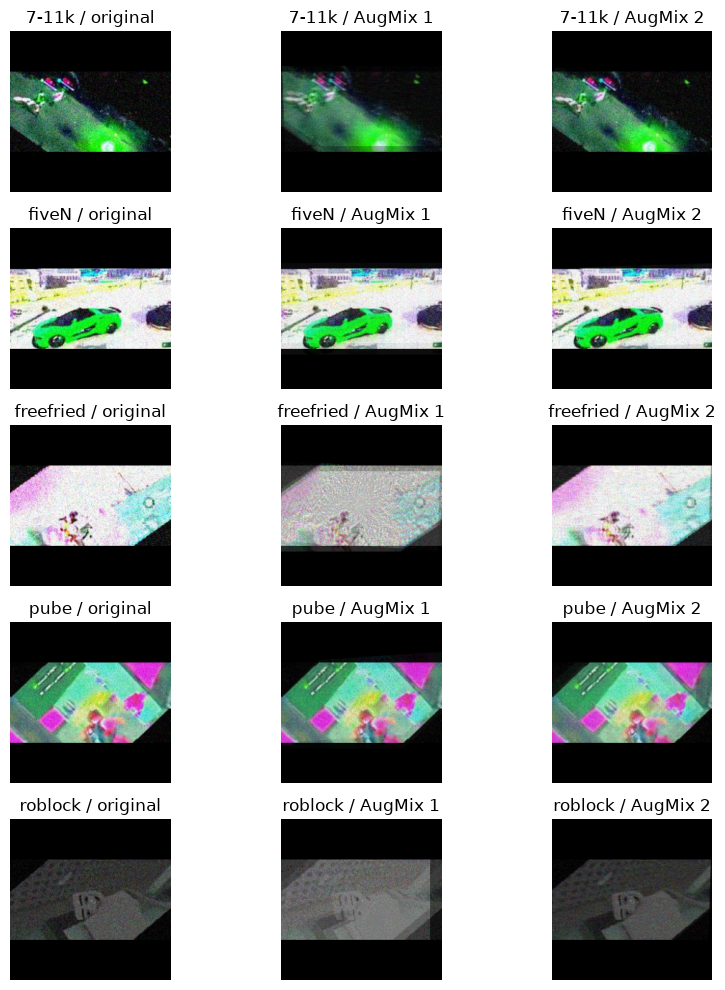

In [3]:
training.seed_everything(123)
fig,axes=plt.subplots(5,3,figsize=(9,10));augment=ConsistencyTransform()
for label in range(5):
    row=train.loc[train.label.eq(label)].iloc[0]
    with Image.open(RAW/'train'/row.file_name) as f:image=f.convert('RGB')
    for j,t in enumerate(augment(image)):
        rgb=(t*torch.tensor(training.STD)[:,None,None]+torch.tensor(training.MEAN)[:,None,None]).clamp(0,1)
        axes[label,j].imshow(rgb.permute(1,2,0));axes[label,j].set_title(f'{training.CLASS_NAMES[label]} / '+['original','AugMix 1','AugMix 2'][j]);axes[label,j].axis('off')
plt.tight_layout();fig.savefig(OUT/'augmix_preview.png',dpi=120);plt.show()


## 4. Pilot fold1 — train แล้ว paired validation

ทั้งสอง references และ candidate ใช้ held-out rows เดียวกัน. Original OOF ใช้ทุกภาพใน fold; stress ใช้ 100 ภาพต่อ class ด้วย seed คงที่. ทุกโมเดลเห็น corruption pixels และ 5-view TTA เหมือนกัน. แบ่ง development 10 conditions กับ final audit 4 conditions. ไม่ใช่สัดส่วน corruption จริงของการแข่งขัน. Stress cache อาจใช้เวลา แต่กลับมาใช้ซ้ำได้.

In [4]:
frame=training.run_fold(RAW,groups,folds,RECIPE,1,OUT,BATCH_SIZE,NUM_WORKERS,
    init_path=HEAVY/'heavy_weighted18/fold1/model.pt')
pilot_scores=validation.fold_comparison(ROOT,RAW,groups,folds,OUT,1,frame,per_class=STRESS_PER_CLASS)
pilot=validation.decision(pilot_scores,full=False)
validation.write_json(OUT/'pilot_decision.json',pilot)
display(pilot_scores.groupby(['phase','procedure']).macro_F1.mean().unstack())
display(pilot)
if not pilot['passed']:print('STOP: pilot ไม่ผ่าน ไม่ฝึก folds ที่เหลือและไม่เปิด Test. ดูรายการ checks ที่ไม่ผ่านก่อนปรับใน run ใหม่')


fold1 epoch 1 / 6 loss 0.23484 seconds 478.1
fold1 epoch 2 / 6 loss 0.17568 seconds 475.3
fold1 epoch 3 / 6 loss 0.15238 seconds 482.9
fold1 epoch 4 / 6 loss 0.13026 seconds 479.1
fold1 epoch 5 / 6 loss 0.11938 seconds 477.7
fold1 epoch 6 / 6 loss 0.1067 seconds 477.9
stress candidate gaussian_1
stress candidate gaussian_2
stress candidate speckle_1
stress candidate speckle_2
stress candidate blur_1
stress candidate blur_2
stress candidate jpeg_1
stress candidate jpeg_2
stress candidate dark_1
stress candidate dark_2
stress weighted gaussian_1
stress weighted gaussian_2
stress weighted speckle_1
stress weighted speckle_2
stress weighted blur_1
stress weighted blur_2
stress weighted jpeg_1
stress weighted jpeg_2
stress weighted dark_1
stress weighted dark_2
stress sampler gaussian_1
stress sampler gaussian_2
stress sampler speckle_1
stress sampler speckle_2
stress sampler blur_1
stress sampler blur_2
stress sampler jpeg_1
stress sampler jpeg_2
stress sampler dark_1
stress sampler dark_2

procedure,augmix_weighted_plus_sampler__tta,heavy_equal_ensemble__tta,resnet18_cosine18__tta
phase,,,
development,0.968943,0.971631,0.959124
original,0.980862,0.979939,0.973701


{'passed': False,
 'full': False,
 'phase': 'development',
 'checks': {'heavy_equal_ensemble__tta/stress_mean': False,
  'heavy_equal_ensemble__tta/worst_condition': True,
  'heavy_equal_ensemble__tta/original_mean': True,
  'heavy_equal_ensemble__tta/per_class': True,
  'heavy_equal_ensemble__tta/fold_wins': False,
  'resnet18_cosine18__tta/stress_mean': True,
  'resnet18_cosine18__tta/worst_condition': True,
  'resnet18_cosine18__tta/original_mean': True,
  'resnet18_cosine18__tta/per_class': True,
  'resnet18_cosine18__tta/fold_wins': True},
 'details': {'heavy_equal_ensemble__tta': {'mean_stress_gain': -0.0026886913791228538,
   'worst_condition_gain': -0.011875587339877924,
   'stress_fold_wins': 0,
   'per_class_deltas': {'F1_7-11k': -0.000978407104349932,
    'F1_fiveN': -0.0005549679298149091,
    'F1_freefried': -0.000888849028592209,
    'F1_pube': 0.004196866170673386,
    'F1_roblock': 0.0028376591540507645}},
  'resnet18_cosine18__tta': {'mean_stress_gain': 0.0098183737324

STOP: pilot ไม่ผ่าน ไม่ฝึก folds ที่เหลือและไม่เปิด Test. ดูรายการ checks ที่ไม่ผ่านก่อนปรับใน run ใหม่


## 5. Full 5-fold confirmation

ใน mode full และ pilot ผ่าน จะทำ folds2–5. เกณฑ์ต้องผ่านทั้งสอง references: original mean ลดไม่เกิน .001, per-class ลดไม่เกิน .01; stress mean เพิ่ม ≥ .005, ชนะอย่างน้อย4/5 folds และไม่มี condition mean ลดเกิน .02. เกณฑ์เหล่านี้เป็น project screening rules ไม่ใช่ statistical guarantee. OOF ถูกใช้ซ้ำจากการเลือกสูตรก่อนหน้า จึงเป็น exploratory comparison.

In [5]:
development_pass=False
development_scores=pilot_scores.copy()
if RUN_MODE=='full' and pilot['passed']:
    parts=[pilot_scores]
    for k in range(2,6):
        frame=training.run_fold(RAW,groups,folds,RECIPE,k,OUT,BATCH_SIZE,NUM_WORKERS,
            init_path=HEAVY/'heavy_weighted18'/f'fold{k}'/'model.pt')
        parts.append(validation.fold_comparison(ROOT,RAW,groups,folds,OUT,k,frame,per_class=STRESS_PER_CLASS))
    development_scores=pd.concat(parts,ignore_index=True)
    development_scores.to_parquet(OUT/'development_scores.parquet',index=False)
    development=validation.decision(development_scores,full=True)
    validation.write_json(OUT/'development_decision.json',development)
    development_pass=development['passed']
    display(development);display(development_scores.groupby(['phase','procedure']).macro_F1.mean().unstack())
else:print('Pilot mode / pilot failed: no full training. ถ้า pilot ผ่าน เปลี่ยน RUN_MODE="full" แล้ว Run All ต่อจาก cache ได้')


Pilot mode / pilot failed: no full training. ถ้า pilot ผ่าน เปลี่ยน RUN_MODE="full" แล้ว Run All ต่อจาก cache ได้


## 6. Final corruption audit — shot/impulse ที่ไม่ใช้ตัดสิน pilot

ใช้โมเดลที่ฝึกเสร็จสูตรเดิมเท่านั้น. Audit เป็น veto: mean gain ≥0 และไม่มี condition mean ลดเกิน .02 เมื่อเทียบทั้งสอง references. ถ้าอ่านผลแล้วปรับสูตร ผลชุดนี้จะไม่ถือว่า untouched อีก. Audit ใช้ accounts ใน folds เดิม จึงเป็น holdout ของ corruption families ไม่ใช่ independent account holdout.

In [6]:
READY=False
audit_scores=None
if RUN_MODE=='full' and development_pass:
    parts=[]
    for k in range(1,6):
        frame=pd.read_parquet(OUT/RECIPE/f'fold{k}'/'oof.parquet')
        parts.append(validation.fold_comparison(ROOT,RAW,groups,folds,OUT,k,frame,phase='audit',per_class=STRESS_PER_CLASS))
    audit_scores=pd.concat(parts,ignore_index=True)
    audit_scores.to_parquet(OUT/'audit_scores.parquet',index=False)
    audit=validation.decision(audit_scores,full=True,phase='audit')
    validation.write_json(OUT/'audit_decision.json',audit)
    READY=audit['passed'];display(audit)
    validation.write_json(OUT/'selection.json',{'ready_for_refit':READY,'procedure':validation.NAME,
        'references':[validation.PRIMARY_BASE,validation.LEGACY_BASE],
        'note':'Synthetic robustness screen, not a guaranteed Public score; no Test observations used'})
else:print('Final audit ยังไม่ถูกเปิด เพราะยังไม่ผ่าน development ครบ5 folds')


Final audit ยังไม่ถูกเปิด เพราะยังไม่ผ่าน development ครบ5 folds


## 7. Evidence: original / development / final audit แยกกัน

mean       min       max
phase       procedure                                                      
development augmix_weighted_plus_sampler__tta  0.968943  0.962116  0.972199
            heavy_equal_ensemble__tta          0.971631  0.965961  0.980041
            resnet18_cosine18__tta             0.959124  0.904485  0.975989
original    augmix_weighted_plus_sampler__tta  0.980862  0.980862  0.980862
            heavy_equal_ensemble__tta          0.979939  0.979939  0.979939
            resnet18_cosine18__tta             0.973701  0.973701  0.973701

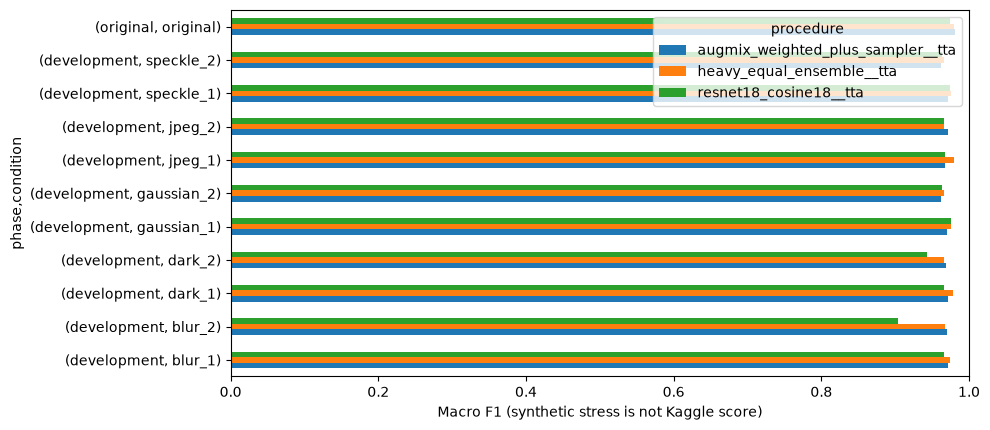

,F1_7-11k,F1_fiveN,F1_freefried,F1_pube,F1_roblock
procedure,,,,,
augmix_weighted_plus_sampler__tta,0.988584,0.977299,0.992844,0.983496,0.962085
heavy_equal_ensemble__tta,0.989562,0.977853,0.993733,0.979299,0.959248
resnet18_cosine18__tta,0.984991,0.976000,0.983871,0.976685,0.946958


Ready: False | Test access requires full mode + all gates + refit below


In [7]:
report=development_scores if audit_scores is None else pd.concat([development_scores,audit_scores],ignore_index=True)
display(report.groupby(['phase','procedure']).macro_F1.agg(['mean','min','max']))
pivot=report.pivot_table(index=['phase','condition'],columns='procedure',values='macro_F1')
ax=pivot.plot.barh(figsize=(10,max(4,len(pivot)*.4)))
ax.set(xlabel='Macro F1 (synthetic stress is not Kaggle score)',xlim=(0,1))
plt.tight_layout();plt.savefig(OUT/'robustness_comparison.png',dpi=120);plt.show()
display(report.loc[report.phase.eq('original')].groupby('procedure')[[c for c in report if c.startswith('F1_')]].mean())
print('Ready:',READY,'| Test access requires full mode + all gates + refit below')


## 8. Full refit เฉพาะเมื่อผ่านทุก gate

เริ่มจาก heavy_weighted18/full/model.pt แล้ว fine-tune 6 epochs ด้วย Train ทั้งหมด. Reuse heavy_sampler18/full/model.pt ใน ensemble. Baseline full checkpoint ไม่มีสิทธิ์ใช้ initialize OOF. ไม่ทำ adaptation หรือ BN recalibration บน Test.

In [8]:
full_path=None
if READY and RUN_FINAL_REFIT:
    full_path=training.fit_fixed(RAW,groups,training.RECIPES[RECIPE],OUT/RECIPE/'full',BATCH_SIZE,NUM_WORKERS,
        init_path=HEAVY/'heavy_weighted18/full/model.pt')
    print('Saved:',full_path)
else:print('No refit: ต้องผ่าน full validation และเปิด RUN_FINAL_REFIT')


No refit: ต้องผ่าน full validation และเปิด RUN_FINAL_REFIT


## 9. Frozen Test inference & combined submission

**เป็น cell แรกที่อ่าน Test** และอ่านไฟล์ submission เดิม. เปิดได้เฉพาะเมื่อ READY และ full checkpoint พร้อม. คง ID/Task1–3/Task5 จาก submission heavy_balance_v1; เปลี่ยนเฉพาะ Task4. Predictions ที่คล้ายไฟล์เดิมไม่ใช้เป็น selection metric. ไม่มีการส่ง Kaggle อัตโนมัติ.

In [9]:
if READY and RUN_EXPORT and full_path is not None:
    assert validation.sha(BASE_SUBMISSION)==BASE_SHA
    test=pd.read_csv(RAW/'test.csv')
    assert test.columns.tolist()==['id','file_name','label'] and test.label.isna().all()
    assert len(test)==25889 and test.id.is_unique and test.file_name.is_unique
    members=[]
    paths={'augmix':full_path,'sampler':HEAVY/'heavy_sampler18/full/model.pt'}
    for member,path in paths.items():
        cache=OUT/f'{member}_test_tta.parquet';meta=cache.with_suffix('.json')
        signature={'model_sha256':validation.sha(path),'manifest_sha256':validation.sha(RAW/'test.csv'),'views':list(training.TTA_VIEWS),'source_hashes':source_hashes}
        if cache.exists():
            assert meta.exists() and json.loads(meta.read_text())==signature
            saved=pd.read_parquet(cache);assert saved.id.tolist()==test.id.tolist()
            p=saved[[f'p{i}' for i in range(5)]].to_numpy()
        else:
            model=training.load_model(path)
            pp=training.predict_views(model,RAW,test,'test',32,NUM_WORKERS)
            p=np.mean(list(pp.values()),axis=0)
            saved=pd.DataFrame(p,columns=[f'p{i}' for i in range(5)]);saved.insert(0,'id',test.id)
            temp=cache.with_suffix('.partial.parquet');saved.to_parquet(temp,index=False);temp.replace(cache)
            validation.write_json(meta,signature)
            del model;gc.collect()
            if training.get_device().type=='mps':torch.mps.empty_cache()
            if training.get_device().type=='cuda':torch.cuda.empty_cache()
        assert np.isfinite(p).all() and p.shape==(len(test),5) and np.allclose(p.sum(1),1,atol=1e-5)
        members.append(p)
    prediction=np.mean(members,axis=0).argmax(1)
    pd.DataFrame({'id':test.id,'task4':prediction}).to_parquet(OUT/'task4_predictions.parquet',index=False)
    with BASE_SUBMISSION.open(newline='') as f:source=list(csv.reader(f))
    assert source[0]==['id','task1','task2','task3','task4','task5']
    assert [r[0] for r in source[1:]]==test.id.tolist()
    rows=[r.copy() for r in source]
    for row,value in zip(rows[1:],prediction):row[4]=str(int(value))
    assert all(a[:4]+a[5:]==b[:4]+b[5:] for a,b in zip(source,rows))
    destination=ROOT/'submission'/f'kaggle_t12345_t4_{RUN_NAME}_t5_directional_gap_cut_v1.csv'
    if destination.exists():
        with destination.open(newline='') as f:assert list(csv.reader(f))==rows,'Refuse overwrite of different predictions'
    else:
        with destination.open('x',newline='') as f:csv.writer(f).writerows(rows)
    with destination.open(newline='') as f:assert list(csv.reader(f))==rows
    validation.write_json(destination.with_suffix('.json'),{'procedure':validation.NAME,'source':str(BASE_SUBMISSION),'source_sha256':BASE_SHA,
        'output_sha256':validation.sha(destination),'rows':len(test),'task5':'directional_gap_cut_v1','kaggle_submitted':False})
    print('Ready for user review:',destination)
else:print('ไม่ได้อ่าน Test หรือสร้าง submission: pilot/validation ยังไม่ผ่าน หรือปิด export')


ไม่ได้อ่าน Test หรือสร้าง submission: pilot/validation ยังไม่ผ่าน หรือปิด export


## 10. Resume / limitations / research

- Checkpoint ทุก epoch: model/optimizer/scheduler/scaler/RNG/history. Run All เดิมเพื่อ resume; epoch ที่ค้างจะเริ่มใหม่. แต่ละ stress condition ที่เสร็จมี cache. ห้ามเขียน run เดียวพร้อมกันสอง kernel.
- Pilot เพิ่ม 1 model ×6 epochs; full รวม5 models ×6 epochs และ full refit เพิ่ม6 epochs. แต่หนึ่ง batch มี3ภาพต่อ original จึงใช้ทรัพยากรมากกว่า CE ปกติ. Stress ต้อง inference 4 models ×10 development conditions ×500 images ×5 TTA ต่อ fold; final audit เพิ่ม4 conditions. ไม่ได้เทรน baseline ใหม่.
- ใช้เฉพาะ Train ในการฝึก/เลือกสูตร. Fixed corruption strengths มาจาก protocol ของงานนี้ที่อิงกลุ่ม corruption ในวรรณกรรม ไม่ได้วัดหรือ fit จาก Test; ห้ามตีความว่าเป็น exact ImageNet-C implementation.
- สูตรก่อนหน้าเคยเลือกจาก OOF ชุดเดียวกัน; pilot และ full เป็น exploratory. Synthetic stress อาจไม่ตรง hidden Test. ผ่านเกณฑ์ช่วยประกอบการตัดสินใจ แต่ไม่รับประกันคะแนนหรือป้องกันเสีย submission ได้ทั้งหมด.
- [AugMix paper](https://arxiv.org/html/1912.02781v2), [Torchvision AugMix](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.AugMix.html), [ImageNet-C evaluation concept](https://arxiv.org/abs/1903.12261).
